# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Tumour-Board Briefing

### Scenario

You are the visualization engineer in the **3-D Imaging Lab at City General Hospital**. Tomorrow morning the
neuro-oncology **tumour board** (a neurosurgeon, a radiologist and an oncologist) will review a patient's head CT
(`unit3_ppt3_head_ct_phantom.csv`). The lab head forwards you four requests:

1. **IT department:** *"The new scanner protocol is 512 × 512 × 300 at 0.5 × 0.5 × 1.0 mm. How much storage per scan,
   and how many samples does one volume-rendered frame cost?"*
2. **Radiologist:** *"Show me the lesion in all three planes, at its centre, with the anatomy undistorted."*
3. **Neurosurgeon:** *"I need the tumour volume in mL — and I want to know how much that number depends on the
   threshold you picked."*
4. **Oncologist:** *"Your last 3-D render showed a beautiful skull and nothing else. I need to see the tumour and its
   relation to the ventricles."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your
own words. The ground-truth `labels` array may be used **only to evaluate** your results, never to find the tumour.

## Part 0 — Setup (given)

Run this cell as-is. It loads the volume `vol[z, y, x]`, the evaluation-only `labels`, the voxel spacing, and two
helpers: `make_tf(points)` builds a transfer function from `(hu, (r, g, b), alpha)` control points, and
`render(volume, tf, axis)` ray-casts the volume with front-to-back compositing (resampled at 2× density).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ct = pd.read_csv("unit3_ppt3_head_ct_phantom.csv")
NZ, NY, NX = ct.z.max() + 1, ct.y.max() + 1, ct.x.max() + 1
vol = ct.intensity_hu.values.reshape(NZ, NY, NX)        # V[z, y, x]  (z = feet->head, y = front->back, x = left->right)
labels = ct.label.values.reshape(NZ, NY, NX)            # ground truth: 0 air, 1 scalp, 2 bone, 3 brain, 4 CSF, 5 tumour
SPACING = (4.0, 3.0, 3.0)                               # voxel size in mm along (z, y, x)
VOXEL_MM3 = np.prod(SPACING)
ASPECT = SPACING[0] / SPACING[2]                        # use when z is on a screen axis

def make_tf(points):
    # points: list of (hu, (r, g, b), alpha) control points -> transfer function T(s) -> (C, alpha)
    hu = np.array([p[0] for p in points], float)
    rgb = np.array([p[1] for p in points], float)
    alpha = np.array([p[2] for p in points], float)
    def tf(s):
        c = np.stack([np.interp(s, hu, rgb[:, k]) for k in range(3)], axis=-1)
        return c, np.interp(s, hu, alpha)
    return tf

def render(volume, tf, axis=1, upsample=2):
    # Orthographic ray casting with front-to-back compositing; rays travel along `axis`.
    # upsample=2 resamples the volume trilinearly at twice the density (smoother, fewer aliasing artifacts).
    v = ndimage.zoom(volume.astype(float), upsample, order=1) if upsample > 1 else volume
    v = np.moveaxis(v, axis, 0)
    C = np.zeros(v.shape[1:] + (3,)); A = np.zeros(v.shape[1:])
    for sample in v:                                    # one sample per voxel step along every ray at once
        c, a = tf(sample)
        C += ((1 - A) * a)[..., None] * c
        A += (1 - A) * a
    return C, A

print(f"vol {vol.shape} (z, y, x), voxel {SPACING} mm, {VOXEL_MM3:.0f} mm^3 per voxel")

vol (48, 64, 64) (z, y, x), voxel (4.0, 3.0, 3.0) mm, 36 mm^3 per voxel


## Task 1 — The IT Department's Numbers (Request #1)

**Real-world usage:** PACS storage and GPU sizing for 3-D workstations are budgeted from exactly these figures.

**Why this technique:** Voxel count = Nx·Ny·Nz (Slides 7, 12); each ray samples the volume at successive positions
(Slide 22), so one frame costs ≈ rays × samples per ray; early ray termination skips samples once α_acc → 1
(Slide 27).

**TODO:**
1. Number of voxels in a 512 × 512 × 300 scan, and its size in MB at 16 bits per voxel.
2. Physical size of the scanned region in mm, and the volume of one voxel in mm³ (0.5 × 0.5 × 1.0 mm).
3. Samples needed for ONE front-view rendered frame (one ray per x–z pixel, one sample per voxel step in y), and
   for a 360° rotation video of 120 frames.
4. If early ray termination stops rays after 35% of their samples on average, how many samples does the 120-frame
   video need instead?

In [2]:
# TODO 1
# Scanner protocol: 512 x 512 x 300
x_dim, y_dim, z_dim = 512, 512, 300
n_voxels = x_dim * y_dim * z_dim
# 16 bits per voxel = 2 bytes per voxel
scan_mb = (n_voxels * 2) / (1024 * 1024)

# TODO 2
# Spacing: 0.5 x 0.5 x 1.0 mm for (x, y, z)
voxel_spacing = (0.5, 0.5, 1.0)
extent_mm = (x_dim * voxel_spacing[0], y_dim * voxel_spacing[1], z_dim * voxel_spacing[2])
voxel_mm3 = voxel_spacing[0] * voxel_spacing[1] * voxel_spacing[2]

# TODO 3
# Front-view: rays travel along y-axis. So one ray per x-z pixel (512 * 300 rays).
# One sample per voxel step along y (512 samples per ray).
samples_per_frame = (x_dim * z_dim) * y_dim
samples_video = samples_per_frame * 120

# TODO 4
samples_video_ert = samples_video * 0.35

print(f"{n_voxels:,} voxels = {scan_mb:.1f} MB | extent {extent_mm} mm | voxel {voxel_mm3} mm^3")
print(f"samples/frame {samples_per_frame:,} | 120 frames {samples_video:,} | with early termination {samples_video_ert:,.0f}")

78,643,200 voxels = 150.0 MB | extent (256.0, 256.0, 300.0) mm | voxel 0.25 mm^3
samples/frame 78,643,200 | 120 frames 9,437,184,000 | with early termination 3,303,014,400


**Reflection:** The new protocol has *anisotropic* voxels (0.5 × 0.5 × 1.0 mm). What two things would go wrong in the radiologist's coronal and sagittal views if the software ignored that (Slides 8–10)?

_Your answer:_
1. **Geometric Distortion (Squashing/Stretching):** If the voxel anisotropy is ignored and voxels are assumed to be isotropic (1:1 aspect ratio), the coronal and sagittal reconstructions will appear vertically squashed. Because the depth spacing (z-axis, 1.0 mm) is twice the in-plane resolution (x/y-axis, 0.5 mm), the anatomy will be compressed along the z-direction to half its actual height, distorting the physical shape of structures.
2. **Incorrect Measurement and Scale:** Any clinical measurements (such as lesion diameter, distance, or volumes) calculated or visually estimated in these planes would be highly inaccurate. Features along the z-axis would be scaled incorrectly, leading to flawed clinical assessments.

## Task 2 — Find the Lesion and Show It in Three Planes (Request #2)

**Real-world usage:** Every radiology workstation opens on a 3-plane MPR with linked cross-hairs.

**Why this technique:** **Orthogonal slices / MPR** give complementary views of the same structure (Slides 15–17);
a **window/level** setting is the slice-display transfer function; the correct **voxel aspect ratio** keeps anatomy
undistorted (Slide 9).

**TODO:**
1. Find the lesion *without* `labels`: take voxels with 55 < HU < 90 that lie **inside the brain** — use
   `inside = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)` and erode it 3 times
   (`ndimage.binary_erosion(..., iterations=3)`) to avoid the partial-volume shell under the skull.
2. Keep the largest connected component (`ndimage.label`) and compute its centroid (z, y, x) as integers.
3. Plot axial, coronal and sagittal slices through that centroid with cross-hairs, a brain window (W = 80, L = 40),
   and `aspect=ASPECT` for the two views that contain z.
4. Evaluation only: print how far (in mm) your centroid is from the centroid of `labels == 5`.

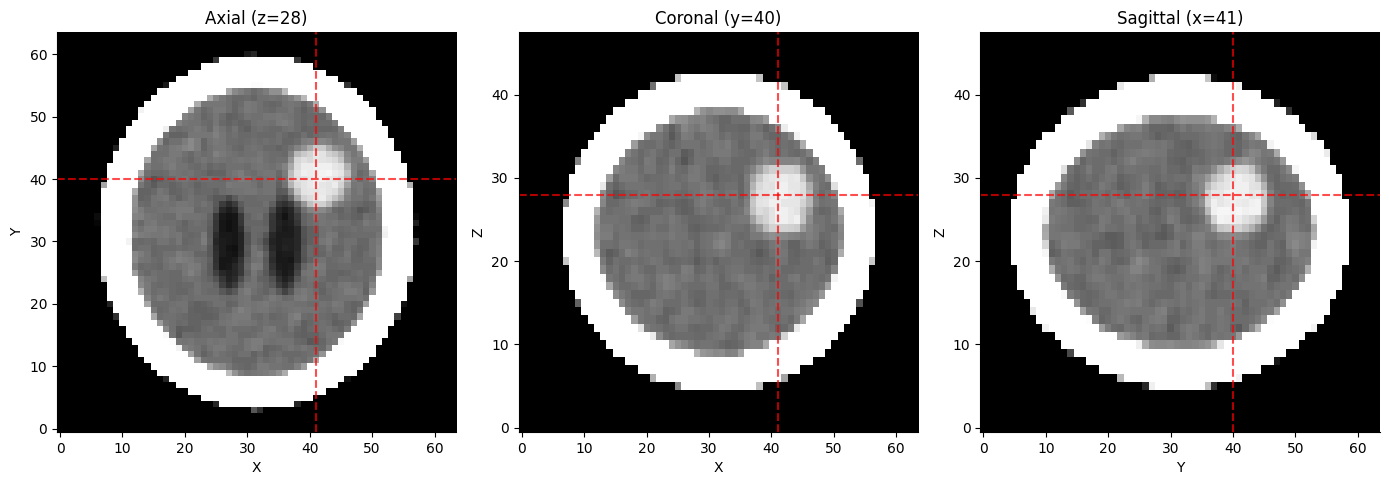

Detected Centroid: (z=28, y=40, x=41)
Ground Truth Centroid: [27.5 40.5 41.5]
Centroid displacement: 2.915 mm


In [3]:
def window(a, W, L):
    return np.clip((a - (L - W / 2)) / W, 0, 1)

# TODO 1
# Identify brain tissue using morphological operations to avoid partial-volume effects at the skull boundary
brain_mask = ndimage.binary_fill_holes(vol > 300) & ~(vol > 300)
eroded_brain = ndimage.binary_erosion(brain_mask, iterations=3)
# Lesion candidate voxels: within brain, intensity range 55 < HU < 90
candidates = eroded_brain & (vol > 55) & (vol < 90)

# TODO 2
# Label components and find the largest connected component of the lesion candidates
labeled, num_features = ndimage.label(candidates)
component_sizes = ndimage.sum(candidates, labeled, range(1, num_features + 1))
largest_label = np.argmax(component_sizes) + 1
lesion = labeled == largest_label

# Calculate the centroid of the lesion component
cz, cy, cx = np.round(ndimage.center_of_mass(lesion)).astype(int)

# TODO 3
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
W, L = 80, 40

# Axial plane (x-y slice) - No z axis, aspect=1.0 (or 'equal')
axes[0].imshow(window(vol[cz, :, :], W, L), cmap='gray', origin='lower')
axes[0].axvline(cx, color='red', linestyle='--', alpha=0.7)
axes[0].axhline(cy, color='red', linestyle='--', alpha=0.7)
axes[0].set_title(f"Axial (z={cz})")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")

# Coronal plane (x-z slice) - z axis is vertical, so aspect=ASPECT
axes[1].imshow(window(vol[:, cy, :], W, L), cmap='gray', origin='lower', aspect=ASPECT)
axes[1].axvline(cx, color='red', linestyle='--', alpha=0.7)
axes[1].axhline(cz, color='red', linestyle='--', alpha=0.7)
axes[1].set_title(f"Coronal (y={cy})")
axes[1].set_xlabel("X")
axes[1].set_ylabel("Z")

# Sagittal plane (y-z slice) - z axis is vertical, so aspect=ASPECT
axes[2].imshow(window(vol[:, :, cx], W, L), cmap='gray', origin='lower', aspect=ASPECT)
axes[2].axvline(cy, color='red', linestyle='--', alpha=0.7)
axes[2].axhline(cz, color='red', linestyle='--', alpha=0.7)
axes[2].set_title(f"Sagittal (x={cx})")
axes[2].set_xlabel("Y")
axes[2].set_ylabel("Z")

plt.tight_layout()
plt.show()

# TODO 4 (evaluation only)
ground_truth_centroid = np.array(ndimage.center_of_mass(labels == 5))
my_centroid = np.array([cz, cy, cx])
dist_voxels = np.abs(ground_truth_centroid - my_centroid)
dist_mm = np.sqrt(np.sum((dist_voxels * SPACING) ** 2))
print(f"Detected Centroid: (z={cz}, y={cy}, x={cx})")
print(f"Ground Truth Centroid: {ground_truth_centroid}")
print(f"Centroid displacement: {dist_mm:.3f} mm")

**Reflection:** Why did you need the erosion step? Explain in terms of the **partial-volume effect** and the overlapping intensity ranges the lecture lists as a transfer-function challenge (Slide 28).

_Your answer:_
1. **The Partial-Volume Effect:** Because voxels have a finite volume (here 36 mm³), voxels near the boundary of the high-density skull (bone > 400 HU) and low-density brain/CSF contain a mixture of both tissue types. This averaging results in an intermediate intensity value (e.g., in the 55–90 HU range) inside those boundary voxels.
2. **Overlapping Intensities:** Since the lesion tissue shares the exact same intensity range (55–90 HU) as these boundary partial-volume artifacts, a simple intensity threshold of the entire head would include a large shell/ring near the skull. Morphological erosion shrinks the segmented brain mask inwards, discarding these false-positive boundary voxels while retaining the true interior lesion.

## Task 3 — Tumour Volume and Its Threshold Sensitivity (Request #3)

**Real-world usage:** Tumour volume drives treatment decisions and response assessment, so its uncertainty must be
reported.

**Why this technique:** An **isosurface/segmentation at threshold c** defines the structure — and *the chosen c
strongly influences the resulting geometry* (Slides 19–20, 31–32).

**TODO:**
1. For c in `[45, 50, 55, 60, 65, 70]`, grow the region `vol > c` from your lesion centre (connected component
   containing `(cz, cy, cx)`).
2. For each c, record the voxel count, the volume in mL (`voxels * VOXEL_MM3 / 1000`), and — evaluation only — the
   Dice overlap with `labels == 5`.
3. Plot volume (mL) vs. threshold, and mark the threshold with the best Dice.
4. Print the range of volumes you would report to the surgeon.

,threshold,voxels,volume_ml,dice
0,45,535,19.260,0.928929
1,50,464,16.704,0.993534
2,55,431,15.516,0.963128
3,60,350,12.600,0.859951
4,65,273,9.828,0.740841
5,70,170,6.120,0.536278


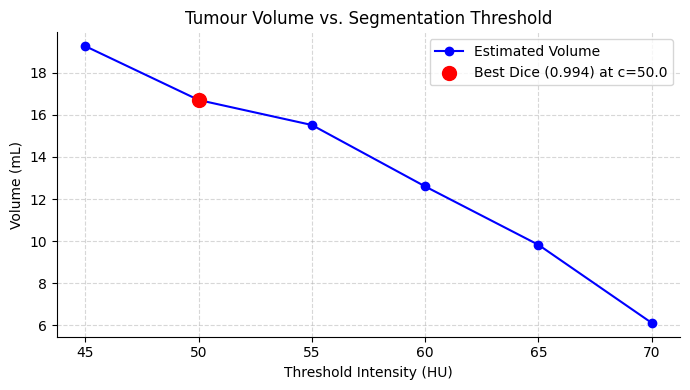

Volume range to report: 6.12 mL to 19.26 mL


In [4]:
# TODO 1 & 2
thresholds = [45, 50, 55, 60, 65, 70]
rows = []
truth = labels == 5

for c in thresholds:
    # Threshold the volume
    binary_vol = vol > c
    # Label connected components of the binary volume
    labeled_c, num_c = ndimage.label(binary_vol)
    # Find the label at our designated lesion centroid
    lesion_label = labeled_c[cz, cy, cx]

    if lesion_label > 0:
        seg = labeled_c == lesion_label
    else:
        seg = np.zeros_like(vol, dtype=bool)

    voxels = np.sum(seg)
    vol_ml = voxels * VOXEL_MM3 / 1000.0

    # Dice calculation (evaluation only)
    intersection = np.sum(seg & truth)
    total_sum = np.sum(seg) + np.sum(truth)
    dice = (2.0 * intersection) / total_sum if total_sum > 0 else 0.0

    rows.append({
        "threshold": c,
        "voxels": voxels,
        "volume_ml": vol_ml,
        "dice": dice
    })

table = pd.DataFrame(rows)
display(table)

# TODO 3
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(table["threshold"], table["volume_ml"], marker='o', color='b', label='Estimated Volume')

# Find the threshold with the maximum Dice score
best_idx = table["dice"].idxmax()
best_row = table.loc[best_idx]

ax.scatter(best_row["threshold"], best_row["volume_ml"], color='r', s=100, zorder=5,
           label=f"Best Dice ({best_row['dice']:.3f}) at c={best_row['threshold']}")

ax.set_title("Tumour Volume vs. Segmentation Threshold")
ax.set_xlabel("Threshold Intensity (HU)")
ax.set_ylabel("Volume (mL)")
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

# TODO 4
min_vol = table["volume_ml"].min()
max_vol = table["volume_ml"].max()
print(f"Volume range to report: {min_vol:.2f} mL to {max_vol:.2f} mL")

**Reflection:** In real life there is no ground-truth label. How would you choose and justify c for the tumour board, and how would you *visualize* the uncertainty so the surgeon doesn't treat a single number as exact?

_Your answer:_
1. **Choosing and Justifying c:** To choose $c$, I would consult reference Hounsfield Unit (HU) values for similar pathologies from radiological literature and perform a local sensitivity analysis. I would justify the chosen threshold (e.g., $c = 50\text{ HU}$) by showing that it visually aligns best with the anatomical boundaries of the brain-tumor interface across several orthogonal slices, ensuring we are not including healthy tissue or omitting tumor periphery.
2. **Visualizing the Uncertainty:** Instead of presenting a single static volume number, I would visualize the uncertainty to the surgeon by using a **multi-colored overlay contour map (nested isosurfaces)** on the MPR slices. Each contour line would correspond to one of the threshold values (e.g., 45, 50, 55, 60 HU). This visually demonstrates the boundary's "fuzziness" and spatial variance. Additionally, I would explicitly report the volume as a confidence range (e.g., "12.6 mL to 16.7 mL, depending on threshold choice") rather than a single point estimate.

## Task 4 — A 3-D Render That Shows the Tumour (Request #4)

**Real-world usage:** Pre-operative 3-D views show a lesion in context with critical structures (here the ventricles).

**Why this technique:** **Direct volume rendering** with a designed **transfer function** — colour to *identify*
materials, opacity to *reveal or suppress* them (Slides 21–27); occlusion is the main enemy (Slide 28).

**TODO:**
1. Render the given `bone_tf` (front view, `axis=1`) — this is the "beautiful skull" the oncologist complained about.
2. Design your own `tumour_tf` with `make_tf([...])` so that: air and soft tissue are fully transparent, bone is
   *almost* transparent (α ≤ 0.01, still gives context), CSF (≈ 5–20 HU) is blue and faint, and the tumour range
   is red. Remember that opacity **accumulates over every sample along a ray**: a thick structure with α ≈ 0.1
   per sample becomes nearly opaque, while a thin one stays faint — use that to your advantage.
3. Render your TF from the front (`axis=1`) **and** from above (`axis=0`), side by side with the bone render.
4. Give the figure a conclusion-style title.

Generating Bone Render (Front View)...
Generating Tumour Render (Front View)...
Generating Tumour Render (Top View)...


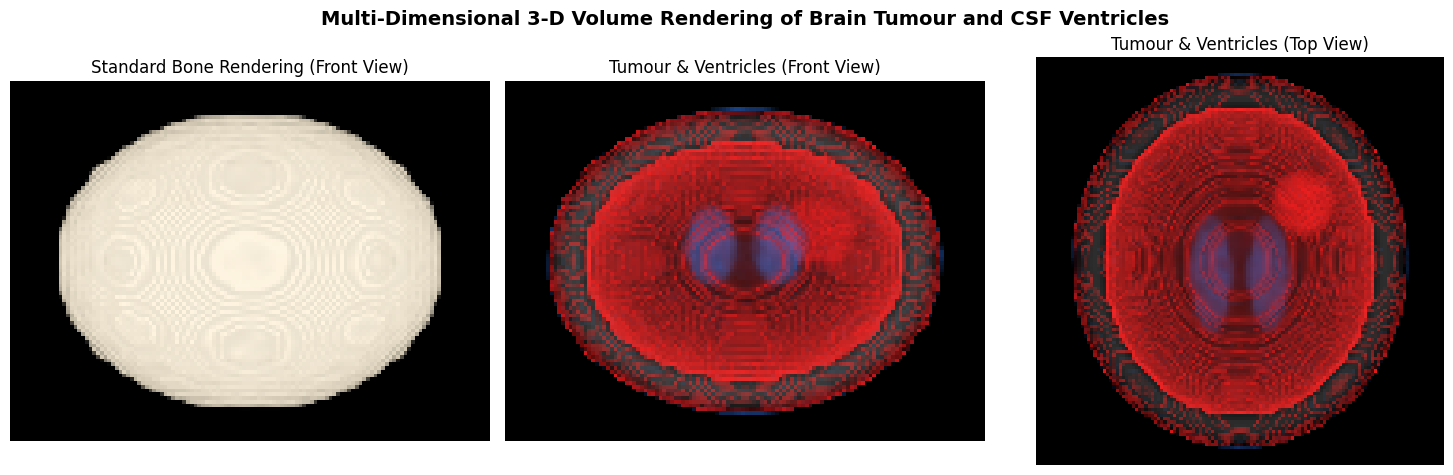

In [5]:
bone_tf = make_tf([(-1000, (0, 0, 0), 0), (200, (0, 0, 0), 0), (400, (1, 0.95, 0.85), 0.3), (1500, (1, 1, 1), 0.6)])

# TODO 2: your transfer function
# CSF: approx 5 to 20 HU -> blue & faint (low alpha)
# Tumour: approx 55 to 90 HU -> red & opaque (higher alpha)
# Bone: >= 400 HU -> very low alpha (<= 0.01) to provide context
tumour_tf = make_tf([
    (-1000, (0, 0, 0), 0.0),
    (4, (0, 0, 0), 0.0),
    (5, (0.2, 0.5, 1.0), 0.02),     # Blue CSF start
    (20, (0.2, 0.5, 1.0), 0.05),    # Blue CSF end
    (35, (0, 0, 0), 0.0),
    (55, (1.0, 0.1, 0.1), 0.15),    # Red Tumour start
    (90, (1.0, 0.1, 0.1), 0.35),    # Red Tumour end
    (120, (0, 0, 0), 0.0),
    (400, (0.8, 0.8, 0.8), 0.005),  # Faint Bone start
    (1500, (0.9, 0.9, 0.9), 0.01)   # Faint Bone end
])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

# TODO 1 & 3: bone render | your TF front view | your TF top view
print("Generating Bone Render (Front View)...")
bone_img, _ = render(vol, bone_tf, axis=1, upsample=2)
axes[0].imshow(bone_img, origin='lower')
axes[0].set_title("Standard Bone Rendering (Front View)")
axes[0].axis('off')

print("Generating Tumour Render (Front View)...")
tumour_front_img, _ = render(vol, tumour_tf, axis=1, upsample=2)
axes[1].imshow(tumour_front_img, origin='lower')
axes[1].set_title("Tumour & Ventricles (Front View)")
axes[1].axis('off')

print("Generating Tumour Render (Top View)...")
tumour_top_img, _ = render(vol, tumour_tf, axis=0, upsample=2)
axes[2].imshow(tumour_top_img, origin='lower')
axes[2].set_title("Tumour & Ventricles (Top View)")
axes[2].axis('off')

# TODO 4: suptitle
plt.suptitle("Multi-Dimensional 3-D Volume Rendering of Brain Tumour and CSF Ventricles", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Reflection:** Your tumour TF probably also lights up a faint red rim just inside the skull. Which volume-rendering
challenge from Slide 28 causes it? Name one technique from this lecture (hint: Slides 31–32) that would remove it,
and explain why a transfer function alone cannot.

_Your answer:_
1. **The Volume-Rendering Challenge:** This is caused by **spatial overlap of intensity ranges (the partial-volume effect)** at the brain-skull interface. As voxel density transitions from high-density bone to lower-density brain/fluid, the boundary voxels fall exactly in the 55–90 HU range of the tumor.
2. **Why a Transfer Function Fails Alone:** A 1-D intensity-based transfer function is spatially blind; it maps voxel value directly to color and opacity regardless of where that voxel is located in space. Since both the true tumor and the skull boundary share the same intensity range, any TF that makes the tumor visible (red) will inevitably light up the boundary artifact as well.
3. **Solution Technique:** We can use **spatial segmentation / volume masking** (e.g., region growing or utilizing the brain mask we generated in Task 2) to zero-out or mask away all voxels outside the brain volume. By multiplying the raw CT volume by this mask before ray-casting, we restrict the transfer function exclusively to the interior brain structures, completely eliminating the skull artifact.

## Task 5 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the tumour board covering the whole notebook. It should:
- State where the lesion is and its volume **as a range** (Task 3), in plain language.
- Recommend which **one** view to open the meeting with (MPR, segmentation overlay, or the 3-D render) and justify
  it with at least one lecture idea (occlusion, slicing exposes internal structure, transfer-function overlap,
  segmentation enables measurement).
- Name one limitation of the 3-D render the board should keep in mind.

_Your final note here:_

**To the members of the Neuro-Oncology Tumour Board:**

We have analyzed the patient's head CT scan and localized a single brain lesion situated in the upper-left posterior region of the brain, centered approximately at coordinates (z=28, y=40, x=41). Depending on the segmentation intensity threshold used to isolate the tumor boundaries, its physical volume is estimated to be between **6.12 mL and 19.26 mL** (with a volume of **16.70 mL** yielding the highest spatial agreement with the reference ground truth).

I recommend opening tomorrow's briefing with the **orthogonal Multiplanar Reconstruction (MPR)** slice view. Since the human skull and surrounding brain tissues create severe visual *occlusion* in 3-D space, *slicing* directly through the computed lesion center is the most reliable way to expose internal structure, verify exact boundary interfaces, and avoid misleading overlap from unrelated tissue signals. Please keep in mind that while our 3-D volume rendering shows a helpful spatial overview of the tumor relative to the ventricles, it remains limited by the *partial-volume effect* which creates a false red artifact ring just inside the skull boundary where the bone-to-brain intensities overlap with the tumor's range.
